In [1]:
pip install requests beautifulsoup4 pandas numpy matplotlib seaborn openpyxl

Note: you may need to restart the kernel to use updated packages.


In [2]:
import requests
from bs4 import BeautifulSoup
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
import requests
from bs4 import BeautifulSoup

url = "https://groww.in/stocks"

response = requests.get(url)

print(response.status_code)

200


In [4]:
html = response.text

print(html[:1000])

<!DOCTYPE html><html lang="en" data-theme="light" style="color-scheme:light"><head><meta charSet="utf-8" data-next-head=""/><meta name="viewport" content="width=device-width, initial-scale=1, minimum-scale=1" data-next-head=""/><link rel="icon" href="/favicon32x32-groww.ico" data-next-head=""/><link rel="preload" as="image" imageSrcSet="//assets-netstorage.groww.in/web-assets/billion_groww_desktop/prod/_next/static/media/stocksHeader.8f2811ec.webp 1x, //assets-netstorage.groww.in/web-assets/billion_groww_desktop/prod/_next/static/media/stocksHeader.8f2811ec.webp 2x" data-next-head=""/><link rel="preload" as="image" imageSrcSet="//assets-netstorage.groww.in/web-assets/billion_groww_desktop/prod/_next/static/media/qrCode.09fc6a50.svg 1x, //assets-netstorage.groww.in/web-assets/billion_groww_desktop/prod/_next/static/media/qrCode.09fc6a50.svg 2x" data-next-head=""/><title data-next-head="">Invest in Stocks &amp; Share Market - Indian Stock Market App: Groww</title><meta name="description"

In [5]:
soup = BeautifulSoup(html, "html.parser")

print(soup.title)

<title data-next-head="">Invest in Stocks &amp; Share Market - Indian Stock Market App: Groww</title>


In [6]:
print(soup.get_text()[:5000])

Invest in Stocks & Share Market - Indian Stock Market App: GrowwStocksInvest in StocksInvest in stocks, ETFs, IPOs with fast orders. Track returns on your stock holdings and view real-time P&L on your positions.IntradayMonitor top intraday performers in real timeETF ScreenerGet the best of Mutual Funds and flexibility of StocksIPOTrack upcoming and ongoing IPOsMTFsBuy now, pay laterStock ScreenerFilter based on RSI, PE ratio and moreStock EventsDividends, bonus, buybacks and moreDemat AccountBegin your stock market journeyShare Market TodayLive news updates from stock marketF&OTrade in Futures & OptionsTrade in F&O using the terminal. View charts, indicators, track your orders , P&L and watchlists in a single spaceIndicesTrack markets across the globeTerminalTrack charts, orders, positions, watchlists in one placeOption chainAnalyse chains, view payoffs, create basketsPledgeGet extra balance for tradingCommoditiesTrade in Crude Oil, Gold, Silver and moreAPI tradingSet up and execute tr

In [7]:
print(len(soup.find_all("a")))

503


In [8]:
for link in soup.find_all("a")[:20]:
    print(link.get_text(strip=True), link.get("href"))

Invest in StocksInvest in stocks, ETFs, IPOs with fast orders. Track returns on your stock holdings and view real-time P&L on your positions. /stocks
IntradayMonitor top intraday performers in real time /stocks/intraday
ETF ScreenerGet the best of Mutual Funds and flexibility of Stocks /etfs
IPOTrack upcoming and ongoing IPOs /ipo
MTFsBuy now, pay later /stocks/mtf
Stock ScreenerFilter based on RSI, PE ratio and more /stocks/filter
Stock EventsDividends, bonus, buybacks and more /stocks/calendar
Demat AccountBegin your stock market journey /open-demat-account
Share Market TodayLive news updates from stock market /share-market-today
Trade in Futures & OptionsTrade in F&O using the terminal. View charts, indicators, track your orders , P&L and watchlists in a single space /futures-and-options
IndicesTrack markets across the globe /indices
TerminalTrack charts, orders, positions, watchlists in one place /charts
Option chainAnalyse chains, view payoffs, create baskets /options/nifty
Pledge

In [9]:
for link in soup.find_all("a"):
    href = link.get("href")
    
    if href and href.startswith("/stocks/"):
        print(link.get_text(" ", strip=True), "→", href)

Intraday Monitor top intraday performers in real time → /stocks/intraday
MTFs Buy now, pay later → /stocks/mtf
Stock Screener Filter based on RSI, PE ratio and more → /stocks/filter
Stock Events Dividends, bonus, buybacks and more → /stocks/calendar
MTF → /stocks/mtf
Stock Screens → /stocks/screens
Tata Motors → /stocks/tata-motors-ltd
NHPC → /stocks/nhpc-ltd
ITC → /stocks/itc-ltd
Wipro → /stocks/wipro-ltd
BSE → /stocks/bse-ltd
NTPC → /stocks/ntpc-green-energy-ltd
IREDA → /stocks/indian-renewable-energy-development-agency-ltd-1569588972606
State Bank of India → /stocks/state-bank-of-india
Adani Power → /stocks/adani-power-ltd
CDSL → /stocks/central-depository-services-india-ltd
Cochin Shipyard → /stocks/cochin-shipyard-ltd
SJVN → /stocks/sjvn-ltd
Most Traded Stocks → /stocks/most-bought-stocks-on-groww
Stocks Market Calender → /stocks/calendar
Tata Steel → /stocks/tata-steel-ltd
Tata Power → /stocks/tata-power-company-ltd
Bharat Heavy Electricals → /stocks/bharat-heavy-electricals-ltd


In [10]:
stock_data = []

for link in soup.find_all("a"):
    href = link.get("href")
    name = link.get_text(" ", strip=True)

    if href and href.startswith("/stocks/"):
        if name and name not in ["Intraday", "MTF", "Stock Screener", "Stock Events"]:
            stock_data.append({
                "Stock_Name": name,
                "Stock_URL": "https://groww.in" + href
            })

print(stock_data[:10])

[{'Stock_Name': 'Intraday Monitor top intraday performers in real time', 'Stock_URL': 'https://groww.in/stocks/intraday'}, {'Stock_Name': 'MTFs Buy now, pay later', 'Stock_URL': 'https://groww.in/stocks/mtf'}, {'Stock_Name': 'Stock Screener Filter based on RSI, PE ratio and more', 'Stock_URL': 'https://groww.in/stocks/filter'}, {'Stock_Name': 'Stock Events Dividends, bonus, buybacks and more', 'Stock_URL': 'https://groww.in/stocks/calendar'}, {'Stock_Name': 'Stock Screens', 'Stock_URL': 'https://groww.in/stocks/screens'}, {'Stock_Name': 'Tata Motors', 'Stock_URL': 'https://groww.in/stocks/tata-motors-ltd'}, {'Stock_Name': 'NHPC', 'Stock_URL': 'https://groww.in/stocks/nhpc-ltd'}, {'Stock_Name': 'ITC', 'Stock_URL': 'https://groww.in/stocks/itc-ltd'}, {'Stock_Name': 'Wipro', 'Stock_URL': 'https://groww.in/stocks/wipro-ltd'}, {'Stock_Name': 'BSE', 'Stock_URL': 'https://groww.in/stocks/bse-ltd'}]


In [11]:
df = pd.DataFrame(stock_data)

In [12]:
df

,Stock_Name,Stock_URL
0,Intraday Monitor top intraday performers in re...,https://groww.in/stocks/intraday
1,"MTFs Buy now, pay later",https://groww.in/stocks/mtf
2,"Stock Screener Filter based on RSI, PE ratio a...",https://groww.in/stocks/filter
3,"Stock Events Dividends, bonus, buybacks and more",https://groww.in/stocks/calendar
4,Stock Screens,https://groww.in/stocks/screens
...,...,...
60,W,https://groww.in/stocks/stocks-list/w
61,X,https://groww.in/stocks/stocks-list/x
62,Y,https://groww.in/stocks/stocks-list/y
63,Z,https://groww.in/stocks/stocks-list/z


In [13]:
import requests
from bs4 import BeautifulSoup
import pandas as pd
import numpy as np

# --------------------------------------------------
# STEP 1: Open Groww Stocks page
# --------------------------------------------------

url = "https://groww.in/stocks"

response = requests.get(url)

print("Main page status code:", response.status_code)

# Create BeautifulSoup object
soup = BeautifulSoup(response.text, "html.parser")


# --------------------------------------------------
# STEP 2: Extract stock names and stock URLs
# --------------------------------------------------

stock_data = []

for link in soup.find_all("a"):

    href = link.get("href")
    name = link.get_text(" ", strip=True)

    # Select links that look like individual stock pages
    if href and href.startswith("/stocks/"):

        # Remove some non-stock pages
        excluded_pages = [
            "/stocks/intraday",
            "/stocks/mtf",
            "/stocks/filter",
            "/stocks/calendar",
            "/stocks/screens",
            "/stocks/sectors",
            "/stocks/most-bought-stocks-on-groww"
        ]

        if href not in excluded_pages and name:

            stock_data.append({
                "Stock_Name": name,
                "Stock_URL": "https://groww.in" + href
            })


# --------------------------------------------------
# STEP 3: Create DataFrame
# --------------------------------------------------

df = pd.DataFrame(stock_data)

# Remove duplicate stock URLs
df = df.drop_duplicates(subset="Stock_URL").reset_index(drop=True)


# --------------------------------------------------
# STEP 4: Check our stock list
# --------------------------------------------------

print("\nNumber of stocks found:", len(df))

print("\nFirst 10 stocks:")
print(df.head(10))


# --------------------------------------------------
# STEP 5: Test ONE individual stock page
# --------------------------------------------------

stock_url = df.loc[0, "Stock_URL"]

print("\nTesting stock URL:")
print(stock_url)

# Request the individual stock page
response_stock = requests.get(stock_url)

print("\nStock page status code:", response_stock.status_code)


# --------------------------------------------------
# STEP 6: Create BeautifulSoup for stock page
# --------------------------------------------------

stock_soup = BeautifulSoup(
    response_stock.text,
    "html.parser"
)


# --------------------------------------------------
# STEP 7: Display text from individual stock page
# --------------------------------------------------

print("\nInformation available on the stock page:\n")

print(
    stock_soup.get_text(
        " ",
        strip=True
    )[:5000]
)

Main page status code: 200

Number of stocks found: 57

First 10 stocks:
            Stock_Name                                          Stock_URL
0          Tata Motors            https://groww.in/stocks/tata-motors-ltd
1                 NHPC                   https://groww.in/stocks/nhpc-ltd
2                  ITC                    https://groww.in/stocks/itc-ltd
3                Wipro                  https://groww.in/stocks/wipro-ltd
4                  BSE                    https://groww.in/stocks/bse-ltd
5                 NTPC      https://groww.in/stocks/ntpc-green-energy-ltd
6                IREDA  https://groww.in/stocks/indian-renewable-energ...
7  State Bank of India        https://groww.in/stocks/state-bank-of-india
8          Adani Power            https://groww.in/stocks/adani-power-ltd
9                 CDSL  https://groww.in/stocks/central-depository-ser...

Testing stock URL:
https://groww.in/stocks/tata-motors-ltd

Stock page status code: 200

Information available o

In [14]:
import requests
from bs4 import BeautifulSoup
import re
import pandas as pd
import time


# --------------------------------------------------
# FUNCTION TO SCRAPE ONE STOCK
# --------------------------------------------------

def scrape_stock(stock_name, stock_url):

    response = requests.get(stock_url)

    soup = BeautifulSoup(response.text, "html.parser")

    # Get all text from the page
    text = soup.get_text(" ", strip=True)


    # --------------------------------------------------
    # Create dictionary for one stock
    # --------------------------------------------------

    data = {
        "Stock_Name": stock_name,
        "Stock_URL": stock_url
    }


    # --------------------------------------------------
    # Extract current price and daily change
    # --------------------------------------------------

    price_pattern = r'₹([\d,]+\.?\d*)\s+([+-]?[\d,]+\.?\d*)\s+\(([\d.]+)%\)'

    price_match = re.search(price_pattern, text)

    if price_match:

        data["Current_Price"] = price_match.group(1)
        data["Change"] = price_match.group(2)
        data["Change_Percent"] = price_match.group(3)


    # --------------------------------------------------
    # Extract today's low
    # --------------------------------------------------

    match = re.search(
        r"Today's low\s+([\d,]+\.?\d*)",
        text
    )

    if match:
        data["Today_Low"] = match.group(1)


    # --------------------------------------------------
    # Extract today's high
    # --------------------------------------------------

    match = re.search(
        r"Today's high\s+([\d,]+\.?\d*)",
        text
    )

    if match:
        data["Today_High"] = match.group(1)


    # --------------------------------------------------
    # Extract 52 week low
    # --------------------------------------------------

    match = re.search(
        r"52 week low\s+([\d,]+\.?\d*)",
        text
    )

    if match:
        data["52_Week_Low"] = match.group(1)


    # --------------------------------------------------
    # Extract 52 week high
    # --------------------------------------------------

    match = re.search(
        r"52 week high\s+([\d,]+\.?\d*)",
        text
    )

    if match:
        data["52_Week_High"] = match.group(1)


    # --------------------------------------------------
    # Extract open price
    # --------------------------------------------------

    match = re.search(
        r"Open price\s+([\d,]+\.?\d*)",
        text
    )

    if match:
        data["Open_Price"] = match.group(1)


    # --------------------------------------------------
    # Extract previous close
    # --------------------------------------------------

    match = re.search(
        r"Previous close\s+([\d,]+\.?\d*)",
        text
    )

    if match:
        data["Previous_Close"] = match.group(1)


    # --------------------------------------------------
    # Extract live volume
    # --------------------------------------------------

    match = re.search(
        r"Live volume\s+([\d,]+)",
        text
    )

    if match:
        data["Volume"] = match.group(1)


    # --------------------------------------------------
    # Extract market cap
    # --------------------------------------------------

    match = re.search(
        r"Market Cap\s+₹([\d,]+)Cr",
        text
    )

    if match:
        data["Market_Cap_Cr"] = match.group(1)


    # --------------------------------------------------
    # Extract ROE
    # --------------------------------------------------

    match = re.search(
        r"ROE\s+([\d.]+)%",
        text
    )

    if match:
        data["ROE"] = match.group(1)


    # --------------------------------------------------
    # Extract P/E Ratio
    # --------------------------------------------------

    match = re.search(
        r"P/E Ratio\(TTM\)\s+([\d.]+)",
        text
    )

    if match:
        data["PE_Ratio"] = match.group(1)


    # --------------------------------------------------
    # Extract EPS
    # --------------------------------------------------

    match = re.search(
        r"EPS\(TTM\)\s+([\d.]+)",
        text
    )

    if match:
        data["EPS"] = match.group(1)


    # --------------------------------------------------
    # Extract P/B Ratio
    # --------------------------------------------------

    match = re.search(
        r"P/B Ratio\s+([\d.]+)",
        text
    )

    if match:
        data["PB_Ratio"] = match.group(1)


    # --------------------------------------------------
    # Extract Dividend Yield
    # --------------------------------------------------

    match = re.search(
        r"Dividend Yield\s+([\d.]+)%",
        text
    )

    if match:
        data["Dividend_Yield"] = match.group(1)


    # --------------------------------------------------
    # Extract Industry P/E
    # --------------------------------------------------

    match = re.search(
        r"Industry P/E\s+([\d.]+)",
        text
    )

    if match:
        data["Industry_PE"] = match.group(1)


    # --------------------------------------------------
    # Extract Book Value
    # --------------------------------------------------

    match = re.search(
        r"Book Value\s+([\d,]+\.?\d*)",
        text
    )

    if match:
        data["Book_Value"] = match.group(1)


    # --------------------------------------------------
    # Extract Debt to Equity
    # --------------------------------------------------

    match = re.search(
        r"Debt to Equity\s+([\d.]+)",
        text
    )

    if match:
        data["Debt_to_Equity"] = match.group(1)


    # --------------------------------------------------
    # Extract Face Value
    # --------------------------------------------------

    match = re.search(
        r"Face Value\s+([\d.]+)",
        text
    )

    if match:
        data["Face_Value"] = match.group(1)


    return data


# --------------------------------------------------
# TEST WITH ONE STOCK
# --------------------------------------------------

test_stock = scrape_stock(
    df.loc[0, "Stock_Name"],
    df.loc[0, "Stock_URL"]
)

print(test_stock)

{'Stock_Name': 'Tata Motors', 'Stock_URL': 'https://groww.in/stocks/tata-motors-ltd', 'Current_Price': '301.10', 'Change': '0.60', 'Change_Percent': '0.20', '52_Week_Low': '294.30', '52_Week_High': '447.79', 'Open_Price': '299.75', 'Previous_Close': '300.50', 'Volume': '76,83,193', 'Market_Cap_Cr': '1,10,671', 'ROE': '5.47', 'PE_Ratio': '1.39', 'EPS': '215.87', 'PB_Ratio': '0.99', 'Dividend_Yield': '1.00', 'Industry_PE': '26.14', 'Book_Value': '304.29', 'Debt_to_Equity': '0.71', 'Face_Value': '2'}


In [15]:
all_stocks = []

for i, row in df.iterrows():

    print(f"Scraping {i+1}/{len(df)}: {row['Stock_Name']}")

    try:

        stock = scrape_stock(
            row["Stock_Name"],
            row["Stock_URL"]
        )

        all_stocks.append(stock)

    except Exception as e:

        print("Error:", e)

    time.sleep(1)

Scraping 1/57: Tata Motors
Scraping 2/57: NHPC
Scraping 3/57: ITC
Scraping 4/57: Wipro
Scraping 5/57: BSE
Scraping 6/57: NTPC
Scraping 7/57: IREDA
Scraping 8/57: State Bank of India
Scraping 9/57: Adani Power
Scraping 10/57: CDSL
Scraping 11/57: Cochin Shipyard
Scraping 12/57: SJVN
Scraping 13/57: Tata Steel
Scraping 14/57: Tata Power
Scraping 15/57: Bharat Heavy Electricals
Scraping 16/57: Indian Oil Corporation
Scraping 17/57: HUDCO
Scraping 18/57: SAIL
Scraping 19/57: Suzlon Energy
Scraping 20/57: Zomato (Eternal)
Scraping 21/57: Yes Bank
Scraping 22/57: Infosys
Scraping 23/57: NBCC
Scraping 24/57: IRCTC
Scraping 25/57: IRFC
Scraping 26/57: Bharat Electronics
Scraping 27/57: HDFC Bank
Scraping 28/57: Vedanta
Scraping 29/57: Reliance Power
Scraping 30/57: Jaiprakash Power Ventures
Scraping 31/57: A
Scraping 32/57: B
Scraping 33/57: C
Scraping 34/57: D
Scraping 35/57: E
Scraping 36/57: F
Scraping 37/57: G
Scraping 38/57: H
Scraping 39/57: I
Scraping 40/57: J
Scraping 41/57: K
Scraping

In [16]:
final_df = pd.DataFrame(all_stocks)

In [17]:
final_df

,Stock_Name,Stock_URL,Current_Price,Change,Change_Percent,52_Week_Low,52_Week_High,Open_Price,Previous_Close,Volume,Market_Cap_Cr,ROE,PE_Ratio,EPS,PB_Ratio,Dividend_Yield,Industry_PE,Book_Value,Debt_to_Equity,Face_Value
0,Tata Motors,https://groww.in/stocks/tata-motors-ltd,301.10,0.60,0.20,294.30,447.79,299.75,300.50,"76,83,193","1,10,671",5.47,1.39,215.87,0.99,1.00,26.14,304.29,0.71,2
1,NHPC,https://groww.in/stocks/nhpc-ltd,76.38,0.03,0.04,71.62,89.22,75.91,76.35,"1,20,31,109","76,744",9.09,17.98,4.25,1.85,2.11,23.44,41.25,1.26,10
2,ITC,https://groww.in/stocks/itc-ltd,259.85,0.55,0.21,255.50,426.40,258.00,259.30,"1,11,16,049","3,24,521",28.53,16.08,16.11,4.48,5.60,35.30,57.87,0.03,1
3,Wipro,https://groww.in/stocks/wipro-ltd,167.40,1.10,0.66,166.00,273.10,165.20,166.30,"84,84,897","1,64,571",14.99,12.39,13.41,1.87,7.01,17.93,88.75,0.23,2
4,BSE,https://groww.in/stocks/bse-ltd,"3,384.00",78.00,2.36,"2,021.50","4,446.80","3,280.00","3,306.00","43,26,473","1,34,846",37.42,47.79,69.18,20.21,0.30,46.80,163.60,0.00,2
5,NTPC,https://groww.in/stocks/ntpc-green-energy-ltd,86.94,-0.78,0.89,84.00,119.95,87.70,87.72,"12,30,861","73,933",2.76,121.86,0.72,3.90,0.00,23.44,22.51,1.67,10
6,IREDA,https://groww.in/stocks/indian-renewable-energ...,111.71,-0.86,0.76,108.65,163.35,112.27,112.57,"33,42,411","31,829",13.59,16.19,7.00,2.31,1.19,19.14,49.07,5.65,10
7,State Bank of India,https://groww.in/stocks/state-bank-of-india,995.70,-14.00,1.39,810.40,"1,234.70","1,000.00","1,009.70","77,71,109","9,27,216",14.29,10.34,97.14,1.58,1.73,12.15,636.49,NaN,1
8,Adani Power,https://groww.in/stocks/adani-power-ltd,209.97,-3.53,1.65,120.00,254.20,212.00,213.50,"1,02,71,412","4,10,764",19.76,28.25,7.54,6.62,0.00,23.44,32.19,0.84,2
9,CDSL,https://groww.in/stocks/central-depository-ser...,"1,360.00",5.00,0.37,"1,116.30","1,673.70","1,343.60","1,355.00","10,40,559","28,320",23.27,60.22,22.50,14.45,0.94,46.80,93.77,0.00,10


In [18]:
final_df = final_df[
    ~final_df["Stock_URL"].str.contains("/stocks/stocks-list/", na=False)
].reset_index(drop=True)

print("Shape:", final_df.shape)
display(final_df.head())

Shape: (30, 20)


,Stock_Name,Stock_URL,Current_Price,Change,Change_Percent,52_Week_Low,52_Week_High,Open_Price,Previous_Close,Volume,Market_Cap_Cr,ROE,PE_Ratio,EPS,PB_Ratio,Dividend_Yield,Industry_PE,Book_Value,Debt_to_Equity,Face_Value
0,Tata Motors,https://groww.in/stocks/tata-motors-ltd,301.10,0.60,0.20,294.30,447.79,299.75,300.50,"76,83,193","1,10,671",5.47,1.39,215.87,0.99,1.00,26.14,304.29,0.71,2
1,NHPC,https://groww.in/stocks/nhpc-ltd,76.38,0.03,0.04,71.62,89.22,75.91,76.35,"1,20,31,109","76,744",9.09,17.98,4.25,1.85,2.11,23.44,41.25,1.26,10
2,ITC,https://groww.in/stocks/itc-ltd,259.85,0.55,0.21,255.50,426.40,258.00,259.30,"1,11,16,049","3,24,521",28.53,16.08,16.11,4.48,5.60,35.30,57.87,0.03,1
3,Wipro,https://groww.in/stocks/wipro-ltd,167.40,1.10,0.66,166.00,273.10,165.20,166.30,"84,84,897","1,64,571",14.99,12.39,13.41,1.87,7.01,17.93,88.75,0.23,2
4,BSE,https://groww.in/stocks/bse-ltd,"3,384.00",78.00,2.36,"2,021.50","4,446.80","3,280.00","3,306.00","43,26,473","1,34,846",37.42,47.79,69.18,20.21,0.30,46.80,163.60,0.00,2


In [19]:
final_df

,Stock_Name,Stock_URL,Current_Price,Change,Change_Percent,52_Week_Low,52_Week_High,Open_Price,Previous_Close,Volume,Market_Cap_Cr,ROE,PE_Ratio,EPS,PB_Ratio,Dividend_Yield,Industry_PE,Book_Value,Debt_to_Equity,Face_Value
0,Tata Motors,https://groww.in/stocks/tata-motors-ltd,301.10,0.60,0.20,294.30,447.79,299.75,300.50,"76,83,193","1,10,671",5.47,1.39,215.87,0.99,1.00,26.14,304.29,0.71,2
1,NHPC,https://groww.in/stocks/nhpc-ltd,76.38,0.03,0.04,71.62,89.22,75.91,76.35,"1,20,31,109","76,744",9.09,17.98,4.25,1.85,2.11,23.44,41.25,1.26,10
2,ITC,https://groww.in/stocks/itc-ltd,259.85,0.55,0.21,255.50,426.40,258.00,259.30,"1,11,16,049","3,24,521",28.53,16.08,16.11,4.48,5.60,35.30,57.87,0.03,1
3,Wipro,https://groww.in/stocks/wipro-ltd,167.40,1.10,0.66,166.00,273.10,165.20,166.30,"84,84,897","1,64,571",14.99,12.39,13.41,1.87,7.01,17.93,88.75,0.23,2
4,BSE,https://groww.in/stocks/bse-ltd,"3,384.00",78.00,2.36,"2,021.50","4,446.80","3,280.00","3,306.00","43,26,473","1,34,846",37.42,47.79,69.18,20.21,0.30,46.80,163.60,0.00,2
5,NTPC,https://groww.in/stocks/ntpc-green-energy-ltd,86.94,-0.78,0.89,84.00,119.95,87.70,87.72,"12,30,861","73,933",2.76,121.86,0.72,3.90,0.00,23.44,22.51,1.67,10
6,IREDA,https://groww.in/stocks/indian-renewable-energ...,111.71,-0.86,0.76,108.65,163.35,112.27,112.57,"33,42,411","31,829",13.59,16.19,7.00,2.31,1.19,19.14,49.07,5.65,10
7,State Bank of India,https://groww.in/stocks/state-bank-of-india,995.70,-14.00,1.39,810.40,"1,234.70","1,000.00","1,009.70","77,71,109","9,27,216",14.29,10.34,97.14,1.58,1.73,12.15,636.49,NaN,1
8,Adani Power,https://groww.in/stocks/adani-power-ltd,209.97,-3.53,1.65,120.00,254.20,212.00,213.50,"1,02,71,412","4,10,764",19.76,28.25,7.54,6.62,0.00,23.44,32.19,0.84,2
9,CDSL,https://groww.in/stocks/central-depository-ser...,"1,360.00",5.00,0.37,"1,116.30","1,673.70","1,343.60","1,355.00","10,40,559","28,320",23.27,60.22,22.50,14.45,0.94,46.80,93.77,0.00,10


In [20]:
print(final_df.isnull().sum())

Stock_Name        0
Stock_URL         0
Current_Price     0
Change            0
Change_Percent    0
52_Week_Low       0
52_Week_High      0
Open_Price        0
Previous_Close    0
Volume            0
Market_Cap_Cr     0
ROE               1
PE_Ratio          1
EPS               1
PB_Ratio          0
Dividend_Yield    0
Industry_PE       0
Book_Value        0
Debt_to_Equity    3
Face_Value        0
dtype: int64


In [21]:
print("Duplicate rows:", final_df.duplicated().sum())

Duplicate rows: 0


In [22]:
final_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 30 entries, 0 to 29
Data columns (total 20 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   Stock_Name      30 non-null     object
 1   Stock_URL       30 non-null     object
 2   Current_Price   30 non-null     object
 3   Change          30 non-null     object
 4   Change_Percent  30 non-null     object
 5   52_Week_Low     30 non-null     object
 6   52_Week_High    30 non-null     object
 7   Open_Price      30 non-null     object
 8   Previous_Close  30 non-null     object
 9   Volume          30 non-null     object
 10  Market_Cap_Cr   30 non-null     object
 11  ROE             29 non-null     object
 12  PE_Ratio        29 non-null     object
 13  EPS             29 non-null     object
 14  PB_Ratio        30 non-null     object
 15  Dividend_Yield  30 non-null     object
 16  Industry_PE     30 non-null     object
 17  Book_Value      30 non-null     object
 18  Debt_to_Equi

In [23]:
numeric_columns = [
    "Current_Price",
    "Change",
    "Change_Percent",
    "52_Week_Low",
    "52_Week_High",
    "Open_Price",
    "Previous_Close",
    "Volume",
    "Market_Cap_Cr",
    "ROE",
    "PE_Ratio",
    "EPS",
    "PB_Ratio",
    "Dividend_Yield",
    "Industry_PE",
    "Book_Value",
    "Debt_to_Equity",
    "Face_Value"
]

for col in numeric_columns:
    final_df[col] = (
        final_df[col]
        .astype(str)
        .str.replace(",", "", regex=False)
        .str.replace("₹", "", regex=False)
        .str.replace("%", "", regex=False)
        .str.strip()
    )
    
    final_df[col] = pd.to_numeric(final_df[col], errors="coerce")

print(final_df.dtypes)

Stock_Name         object
Stock_URL          object
Current_Price     float64
Change            float64
Change_Percent    float64
52_Week_Low       float64
52_Week_High      float64
Open_Price        float64
Previous_Close    float64
Volume              int64
Market_Cap_Cr       int64
ROE               float64
PE_Ratio          float64
EPS               float64
PB_Ratio          float64
Dividend_Yield    float64
Industry_PE       float64
Book_Value        float64
Debt_to_Equity    float64
Face_Value          int64
dtype: object


In [24]:
final_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 30 entries, 0 to 29
Data columns (total 20 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Stock_Name      30 non-null     object 
 1   Stock_URL       30 non-null     object 
 2   Current_Price   30 non-null     float64
 3   Change          30 non-null     float64
 4   Change_Percent  30 non-null     float64
 5   52_Week_Low     30 non-null     float64
 6   52_Week_High    30 non-null     float64
 7   Open_Price      30 non-null     float64
 8   Previous_Close  30 non-null     float64
 9   Volume          30 non-null     int64  
 10  Market_Cap_Cr   30 non-null     int64  
 11  ROE             29 non-null     float64
 12  PE_Ratio        29 non-null     float64
 13  EPS             29 non-null     float64
 14  PB_Ratio        30 non-null     float64
 15  Dividend_Yield  30 non-null     float64
 16  Industry_PE     30 non-null     float64
 17  Book_Value      30 non-null     float

In [25]:
# Check for negative values in important financial columns

print("Negative Current Prices:")
print(final_df[final_df["Current_Price"] < 0])

print("\nNegative 52-Week Low:")
print(final_df[final_df["52_Week_Low"] < 0])

print("\nNegative 52-Week High:")
print(final_df[final_df["52_Week_High"] < 0])

print("\nNegative Volume:")
print(final_df[final_df["Volume"] < 0])

print("\nNegative Market Cap:")
print(final_df[final_df["Market_Cap_Cr"] < 0])

Negative Current Prices:
Empty DataFrame
Columns: [Stock_Name, Stock_URL, Current_Price, Change, Change_Percent, 52_Week_Low, 52_Week_High, Open_Price, Previous_Close, Volume, Market_Cap_Cr, ROE, PE_Ratio, EPS, PB_Ratio, Dividend_Yield, Industry_PE, Book_Value, Debt_to_Equity, Face_Value]
Index: []

Negative 52-Week Low:
Empty DataFrame
Columns: [Stock_Name, Stock_URL, Current_Price, Change, Change_Percent, 52_Week_Low, 52_Week_High, Open_Price, Previous_Close, Volume, Market_Cap_Cr, ROE, PE_Ratio, EPS, PB_Ratio, Dividend_Yield, Industry_PE, Book_Value, Debt_to_Equity, Face_Value]
Index: []

Negative 52-Week High:
Empty DataFrame
Columns: [Stock_Name, Stock_URL, Current_Price, Change, Change_Percent, 52_Week_Low, 52_Week_High, Open_Price, Previous_Close, Volume, Market_Cap_Cr, ROE, PE_Ratio, EPS, PB_Ratio, Dividend_Yield, Industry_PE, Book_Value, Debt_to_Equity, Face_Value]
Index: []

Negative Volume:
Empty DataFrame
Columns: [Stock_Name, Stock_URL, Current_Price, Change, Change_Percen

In [26]:
print(
    final_df[
        final_df["52_Week_Low"] > final_df["52_Week_High"]
    ][["Stock_Name", "52_Week_Low", "52_Week_High"]]
)

Empty DataFrame
Columns: [Stock_Name, 52_Week_Low, 52_Week_High]
Index: []


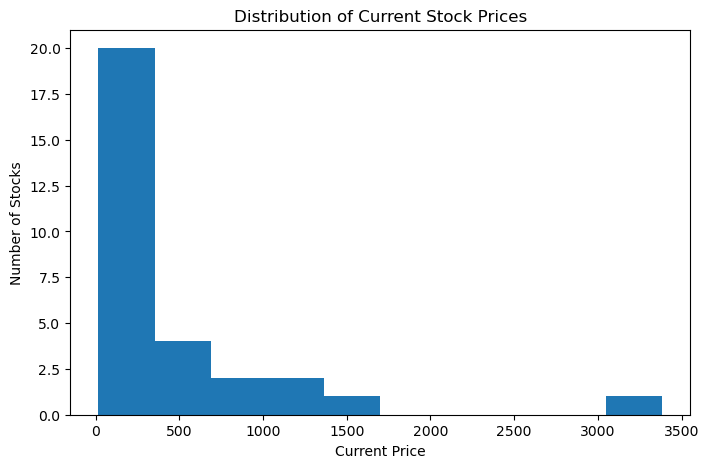

In [27]:
plt.figure(figsize=(8,5))

plt.hist(final_df["Current_Price"], bins=10)

plt.xlabel("Current Price")
plt.ylabel("Number of Stocks")
plt.title("Distribution of Current Stock Prices")

plt.show()

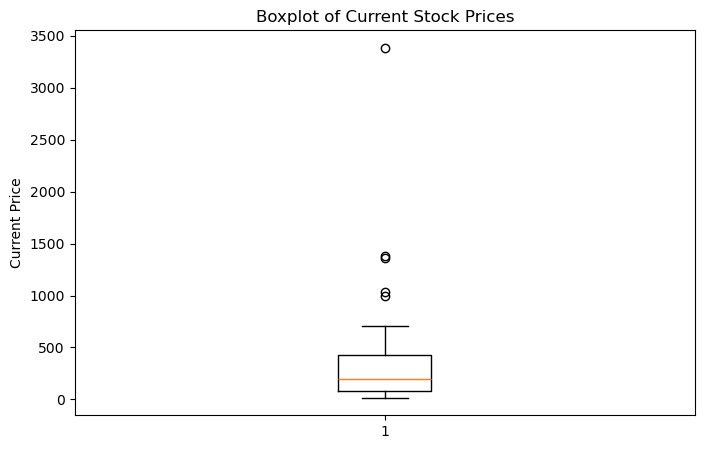

In [28]:
plt.figure(figsize=(8,5))

plt.boxplot(final_df["Current_Price"])

plt.ylabel("Current Price")
plt.title("Boxplot of Current Stock Prices")

plt.show()

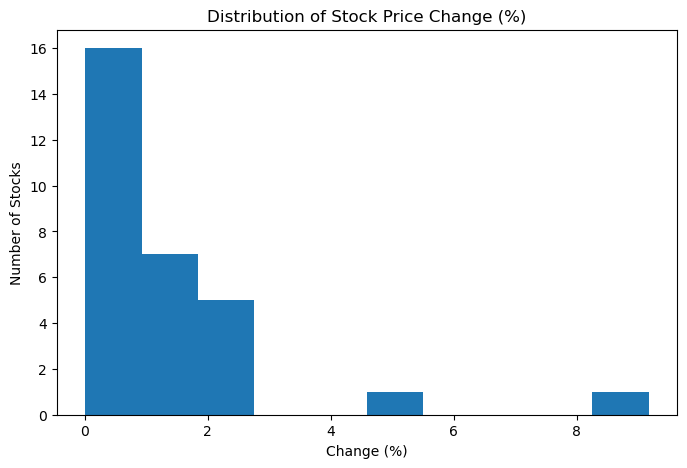

In [29]:
plt.figure(figsize=(8,5))

plt.hist(final_df["Change_Percent"], bins=10)

plt.xlabel("Change (%)")
plt.ylabel("Number of Stocks")
plt.title("Distribution of Stock Price Change (%)")

plt.show()

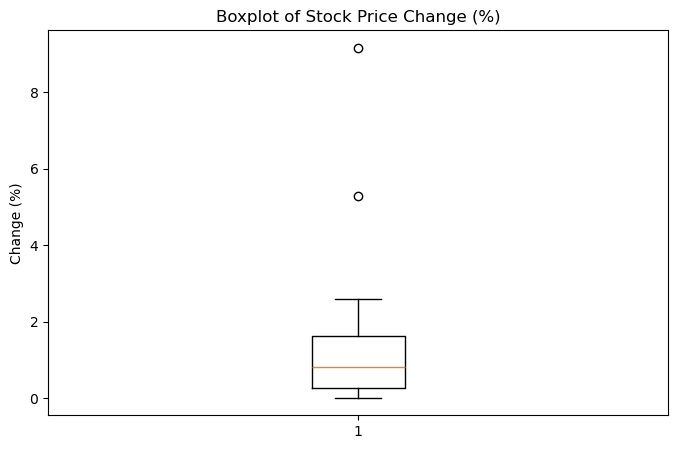

In [30]:
plt.figure(figsize=(8,5))

plt.boxplot(final_df["Change_Percent"])

plt.ylabel("Change (%)")
plt.title("Boxplot of Stock Price Change (%)")

plt.show()

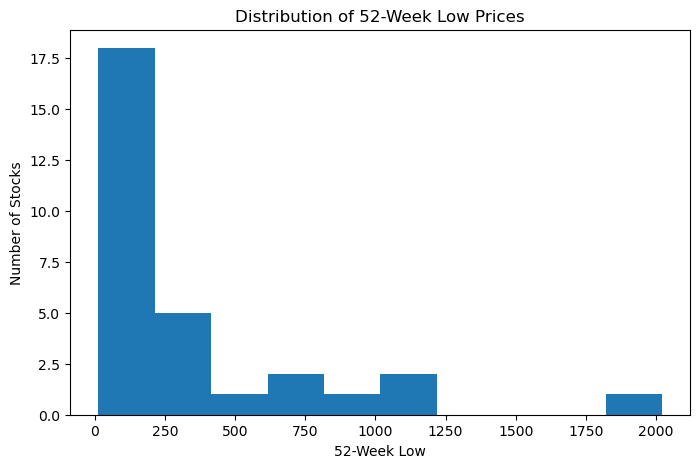

In [31]:
plt.figure(figsize=(8,5))

plt.hist(final_df["52_Week_Low"], bins=10)

plt.xlabel("52-Week Low")
plt.ylabel("Number of Stocks")
plt.title("Distribution of 52-Week Low Prices")

plt.show()

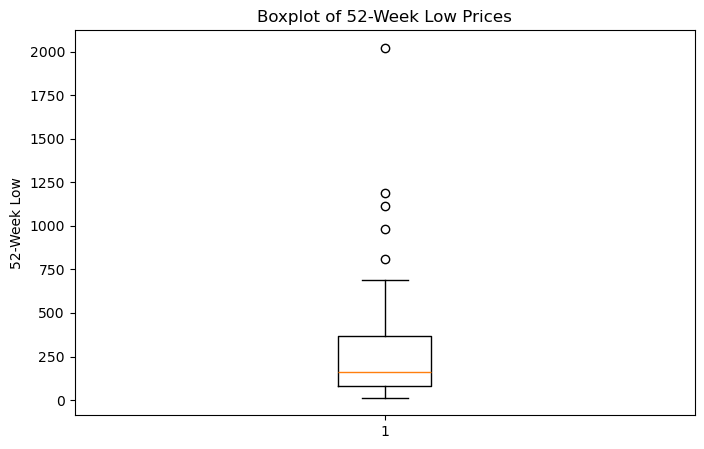

In [32]:
plt.figure(figsize=(8,5))

plt.boxplot(final_df["52_Week_Low"])

plt.ylabel("52-Week Low")
plt.title("Boxplot of 52-Week Low Prices")

plt.show()

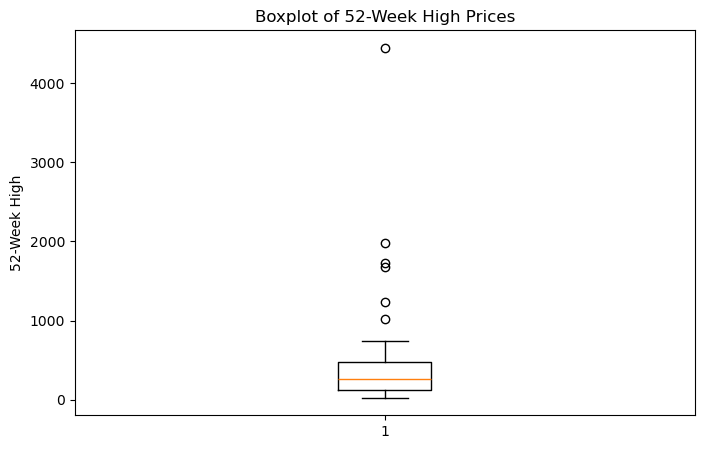

In [33]:
plt.figure(figsize=(8,5))

plt.boxplot(final_df["52_Week_High"])

plt.ylabel("52-Week High")
plt.title("Boxplot of 52-Week High Prices")

plt.show()

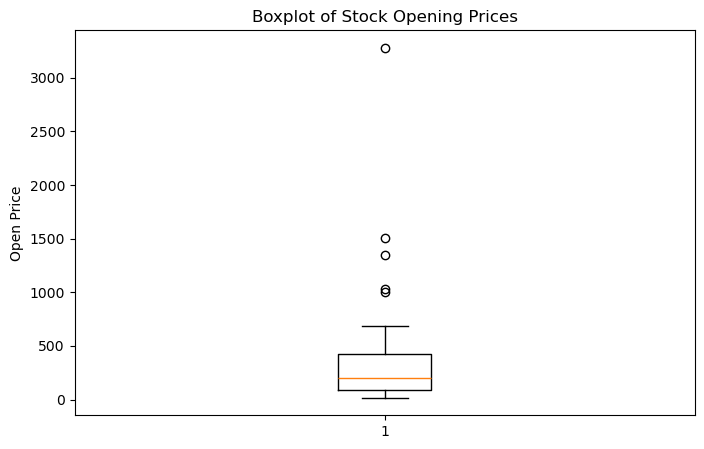

In [34]:
plt.figure(figsize=(8,5))

plt.boxplot(final_df["Open_Price"])

plt.ylabel("Open Price")
plt.title("Boxplot of Stock Opening Prices")

plt.show()

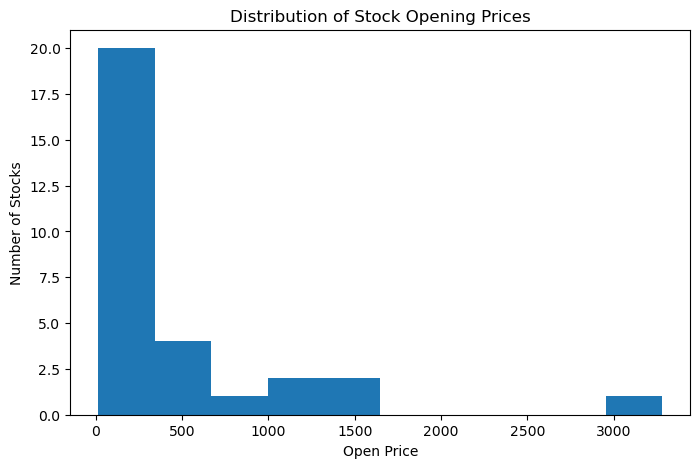

In [35]:
plt.figure(figsize=(8,5))

plt.hist(final_df["Open_Price"], bins=10)

plt.xlabel("Open Price")
plt.ylabel("Number of Stocks")
plt.title("Distribution of Stock Opening Prices")

plt.show()

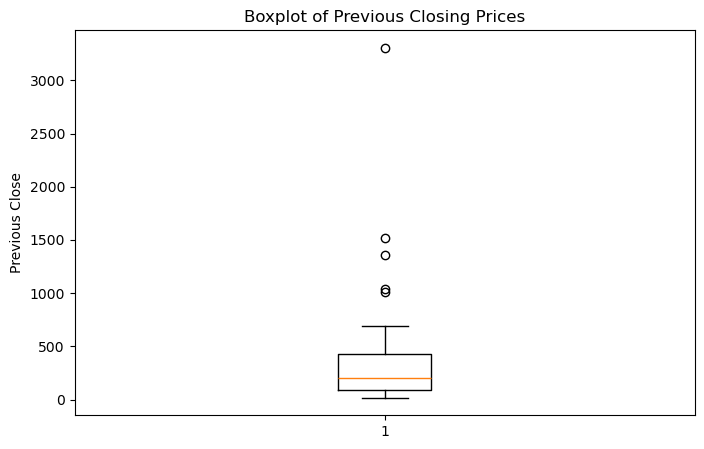

In [36]:
plt.figure(figsize=(8,5))

plt.boxplot(final_df["Previous_Close"])

plt.ylabel("Previous Close")
plt.title("Boxplot of Previous Closing Prices")

plt.show()

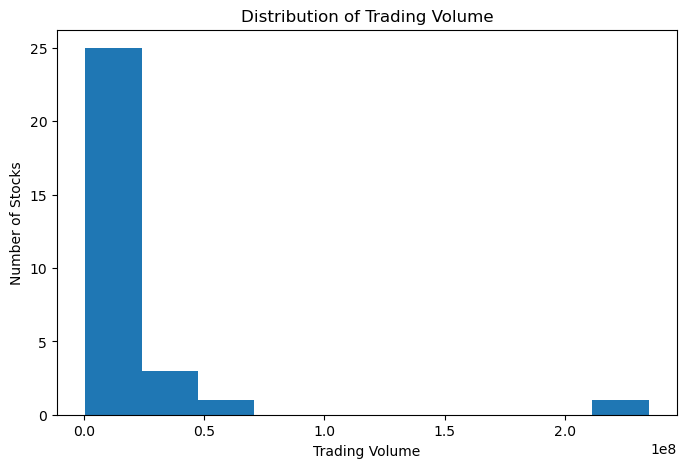

In [37]:
plt.figure(figsize=(8,5))

plt.hist(final_df["Volume"], bins=10)

plt.xlabel("Trading Volume")
plt.ylabel("Number of Stocks")
plt.title("Distribution of Trading Volume")

plt.show()

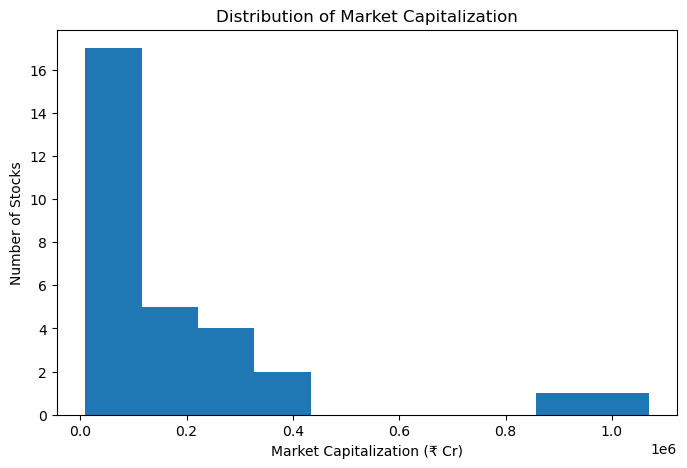

In [38]:
plt.figure(figsize=(8,5))

plt.hist(final_df["Market_Cap_Cr"], bins=10)

plt.xlabel("Market Capitalization (₹ Cr)")
plt.ylabel("Number of Stocks")
plt.title("Distribution of Market Capitalization")

plt.show()

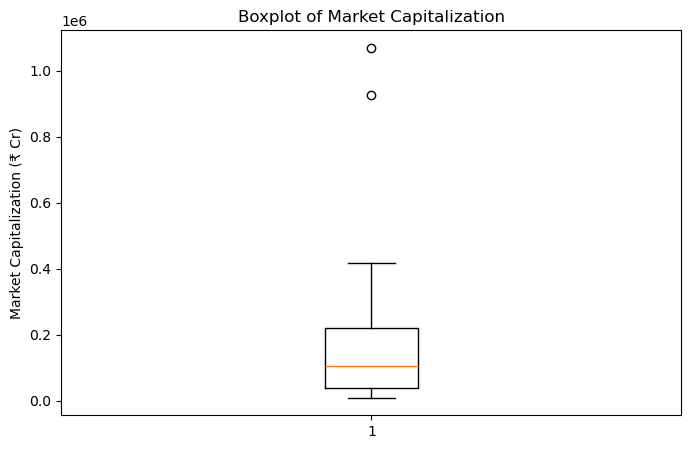

In [39]:
plt.figure(figsize=(8,5))

plt.boxplot(final_df["Market_Cap_Cr"])

plt.ylabel("Market Capitalization (₹ Cr)")
plt.title("Boxplot of Market Capitalization")

plt.show()

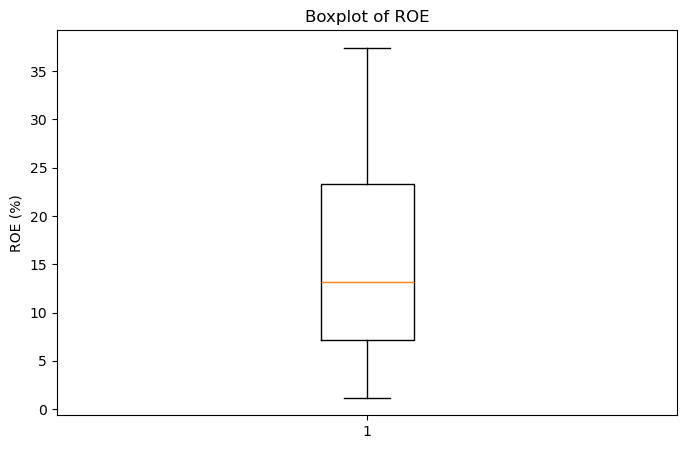

In [40]:
plt.figure(figsize=(8,5))

plt.boxplot(final_df["ROE"].dropna())

plt.ylabel("ROE (%)")
plt.title("Boxplot of ROE")

plt.show()

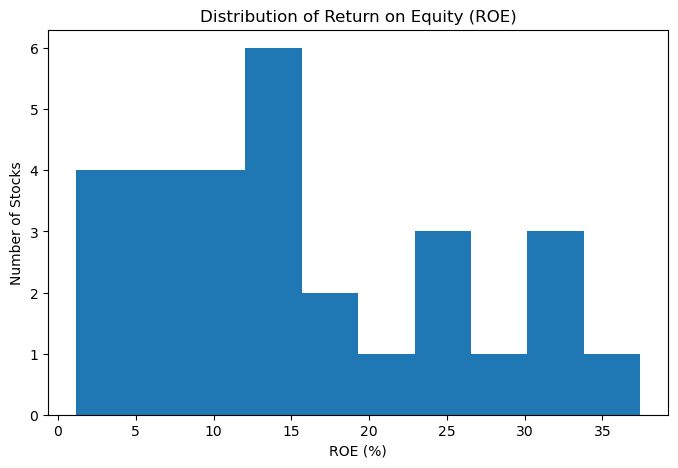

In [41]:
plt.figure(figsize=(8,5))

plt.hist(final_df["ROE"].dropna(), bins=10)

plt.xlabel("ROE (%)")
plt.ylabel("Number of Stocks")
plt.title("Distribution of Return on Equity (ROE)")

plt.show()

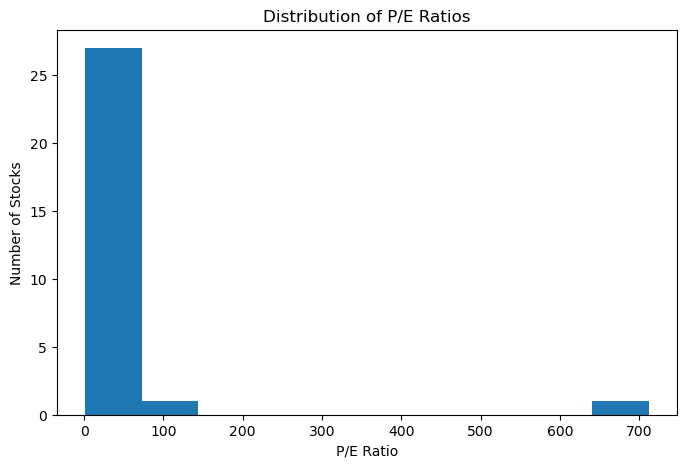

In [42]:
plt.figure(figsize=(8,5))

plt.hist(final_df["PE_Ratio"].dropna(), bins=10)

plt.xlabel("P/E Ratio")
plt.ylabel("Number of Stocks")
plt.title("Distribution of P/E Ratios")

plt.show()

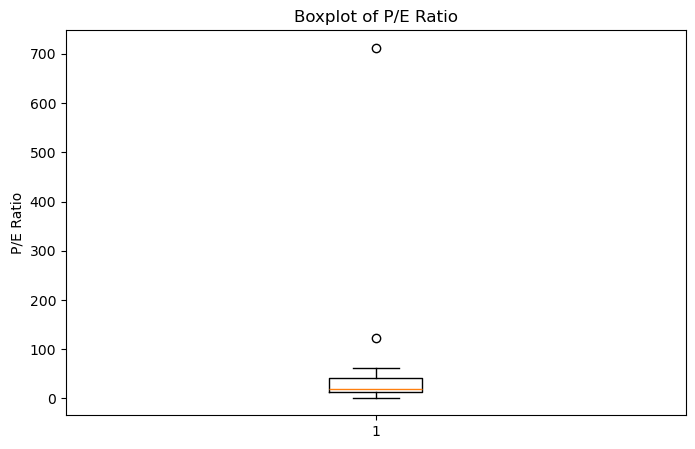

In [43]:
plt.figure(figsize=(8,5))

plt.boxplot(final_df["PE_Ratio"].dropna())

plt.ylabel("P/E Ratio")
plt.title("Boxplot of P/E Ratio")

plt.show()


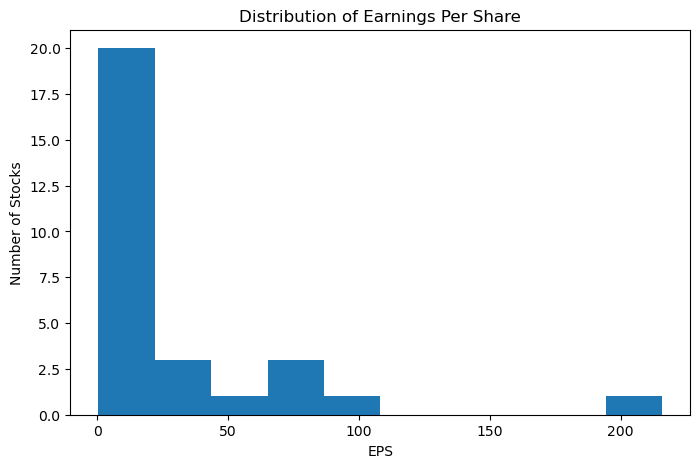

In [44]:
plt.figure(figsize=(8,5))

plt.hist(final_df["EPS"].dropna(), bins=10)

plt.xlabel("EPS")
plt.ylabel("Number of Stocks")
plt.title("Distribution of Earnings Per Share")

plt.show()

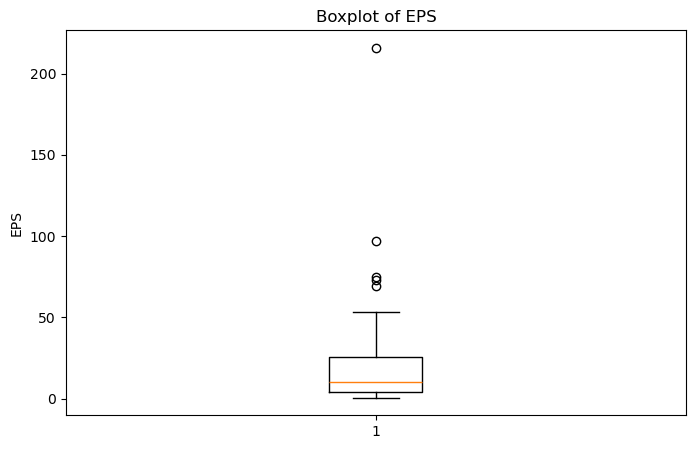

In [45]:
plt.figure(figsize=(8,5))

plt.boxplot(final_df["EPS"].dropna())

plt.ylabel("EPS")
plt.title("Boxplot of EPS")

plt.show()

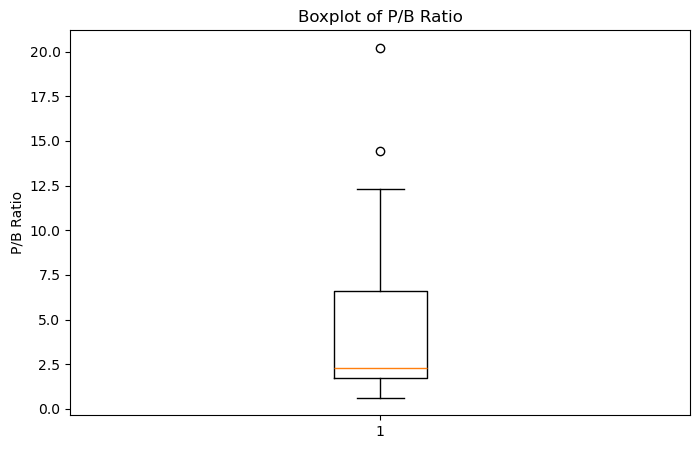

In [46]:
plt.figure(figsize=(8,5))

plt.boxplot(final_df["PB_Ratio"])

plt.ylabel("P/B Ratio")
plt.title("Boxplot of P/B Ratio")

plt.show()

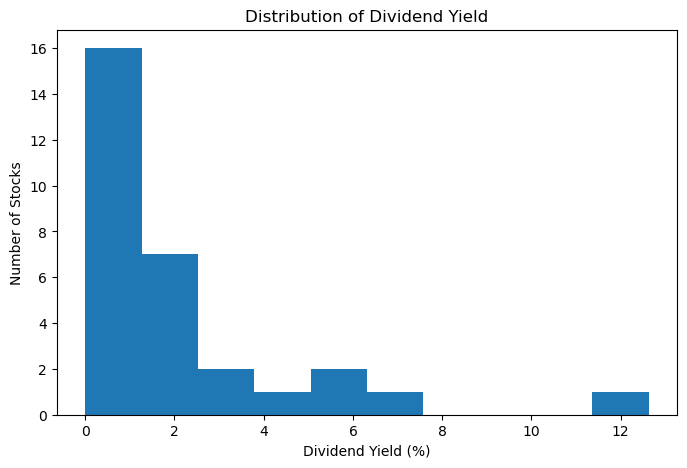

In [47]:
plt.figure(figsize=(8,5))

plt.hist(final_df["Dividend_Yield"], bins=10)

plt.xlabel("Dividend Yield (%)")
plt.ylabel("Number of Stocks")
plt.title("Distribution of Dividend Yield")

plt.show()

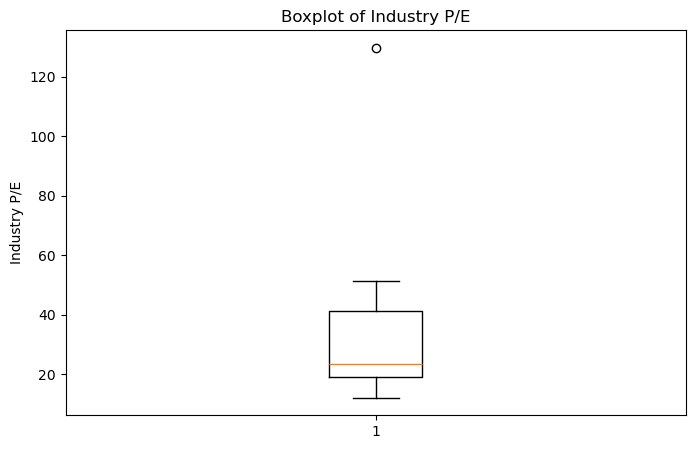

In [48]:
plt.figure(figsize=(8,5))

plt.boxplot(final_df["Industry_PE"])

plt.ylabel("Industry P/E")
plt.title("Boxplot of Industry P/E")

plt.show()

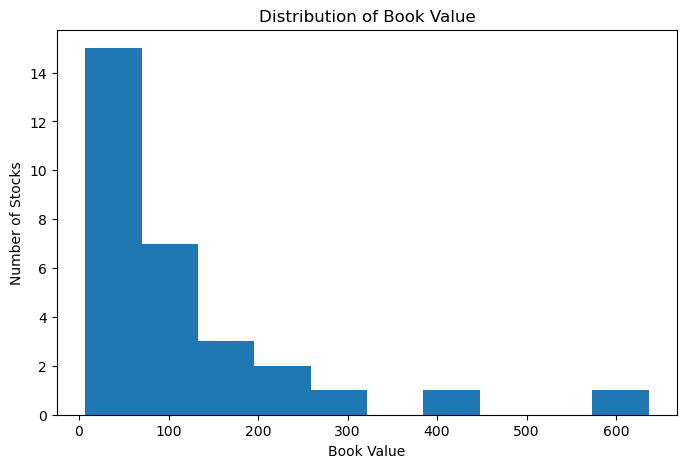

In [49]:
plt.figure(figsize=(8,5))

plt.hist(final_df["Book_Value"], bins=10)

plt.xlabel("Book Value")
plt.ylabel("Number of Stocks")
plt.title("Distribution of Book Value")

plt.show()

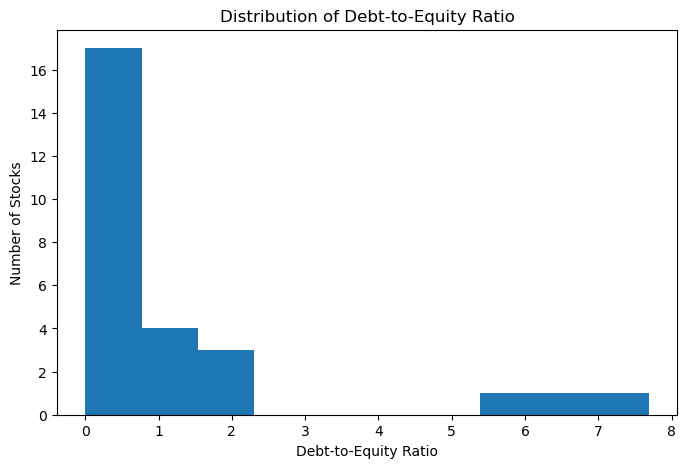

In [50]:
plt.figure(figsize=(8,5))

plt.hist(final_df["Debt_to_Equity"].dropna(), bins=10)

plt.xlabel("Debt-to-Equity Ratio")
plt.ylabel("Number of Stocks")
plt.title("Distribution of Debt-to-Equity Ratio")

plt.show()

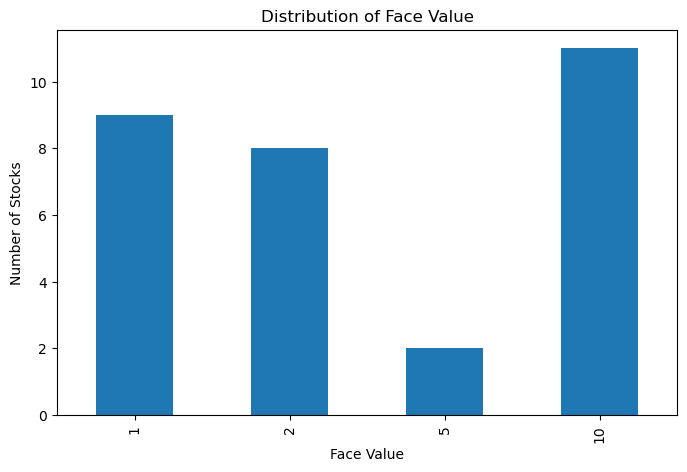

In [51]:
final_df["Face_Value"].value_counts().sort_index().plot(
    kind="bar",
    figsize=(8,5)
)

plt.xlabel("Face Value")
plt.ylabel("Number of Stocks")
plt.title("Distribution of Face Value")

plt.show()

**BIVARIATE ANALYSIS**

In [52]:
final_df["Distance_From_52W_High"] = (
    (final_df["52_Week_High"] - final_df["Current_Price"])
    / final_df["52_Week_High"]
) * 100

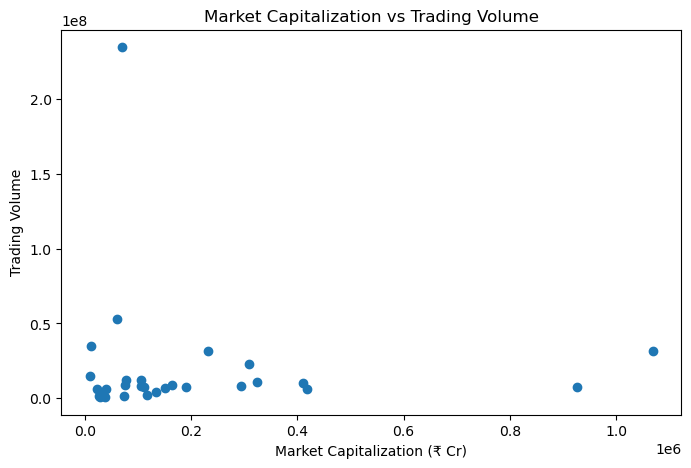

In [53]:
plt.figure(figsize=(8,5))

plt.scatter(
    final_df["Market_Cap_Cr"],
    final_df["Volume"]
)

plt.xlabel("Market Capitalization (₹ Cr)")
plt.ylabel("Trading Volume")
plt.title("Market Capitalization vs Trading Volume")

plt.show()

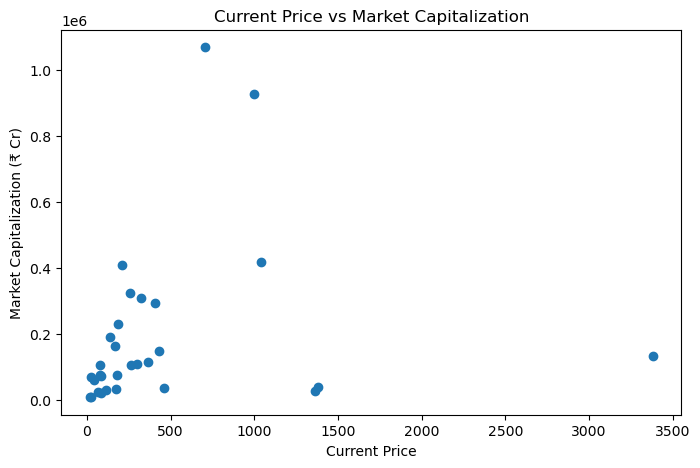

In [54]:
plt.figure(figsize=(8,5))

plt.scatter(
    final_df["Current_Price"],
    final_df["Market_Cap_Cr"]
)

plt.xlabel("Current Price")
plt.ylabel("Market Capitalization (₹ Cr)")
plt.title("Current Price vs Market Capitalization")

plt.show()

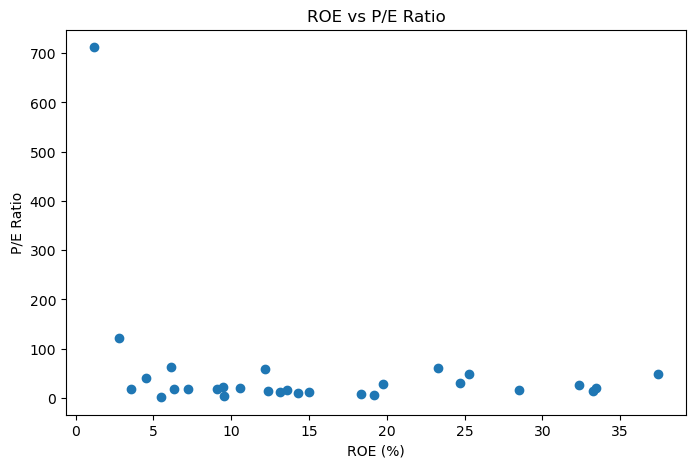

In [55]:
plt.figure(figsize=(8,5))

plt.scatter(
    final_df["ROE"],
    final_df["PE_Ratio"]
)

plt.xlabel("ROE (%)")
plt.ylabel("P/E Ratio")
plt.title("ROE vs P/E Ratio")

plt.show()

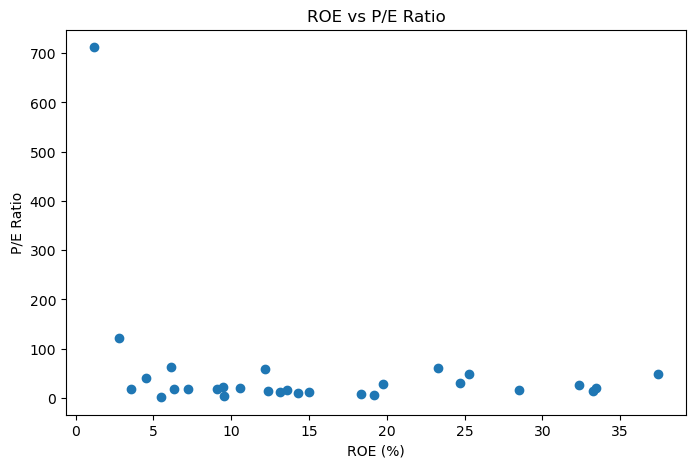

In [56]:
temp = final_df[["ROE", "PE_Ratio"]].dropna()

plt.figure(figsize=(8,5))

plt.scatter(
    temp["ROE"],
    temp["PE_Ratio"]
)

plt.xlabel("ROE (%)")
plt.ylabel("P/E Ratio")
plt.title("ROE vs P/E Ratio")

plt.show()

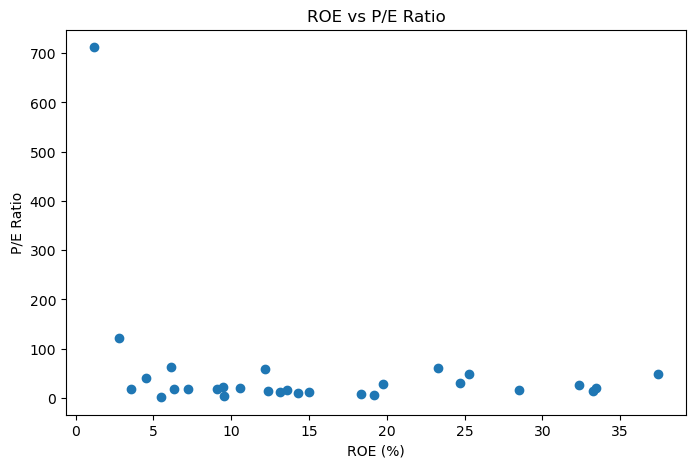

In [57]:
temp = final_df[["ROE", "PE_Ratio"]].dropna()

plt.figure(figsize=(8,5))

plt.scatter(
    temp["ROE"],
    temp["PE_Ratio"]
)

plt.xlabel("ROE (%)")
plt.ylabel("P/E Ratio")
plt.title("ROE vs P/E Ratio")

plt.show()

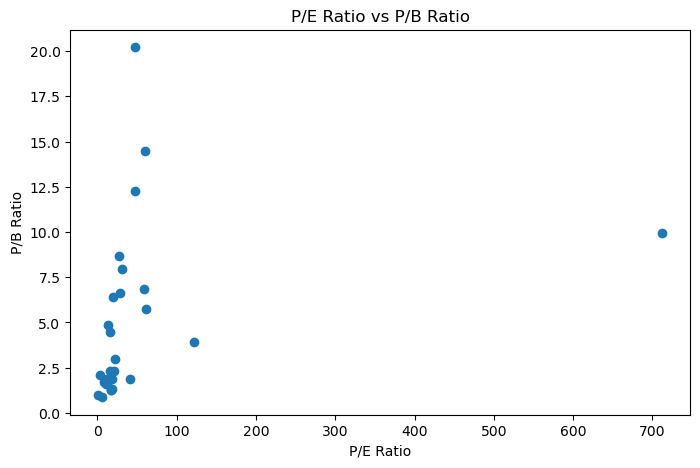

In [58]:
temp = final_df[["PE_Ratio", "PB_Ratio"]].dropna()

plt.figure(figsize=(8,5))

plt.scatter(
    temp["PE_Ratio"],
    temp["PB_Ratio"]
)

plt.xlabel("P/E Ratio")
plt.ylabel("P/B Ratio")
plt.title("P/E Ratio vs P/B Ratio")

plt.show()

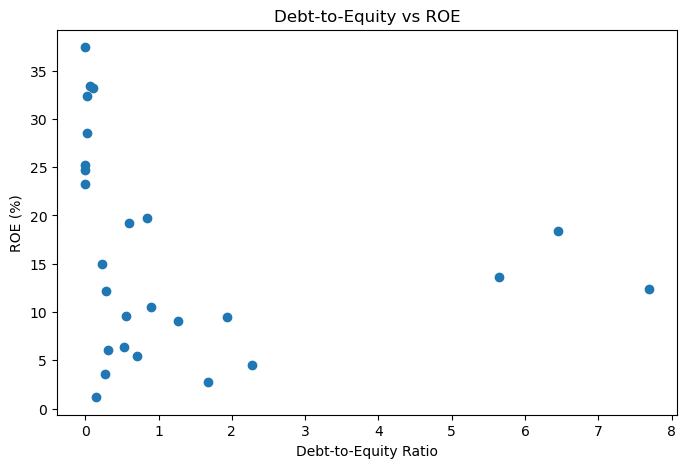

In [59]:
temp = final_df[["Debt_to_Equity", "ROE"]].dropna()

plt.figure(figsize=(8,5))

plt.scatter(
    temp["Debt_to_Equity"],
    temp["ROE"]
)

plt.xlabel("Debt-to-Equity Ratio")
plt.ylabel("ROE (%)")
plt.title("Debt-to-Equity vs ROE")

plt.show()

In [60]:
final_df[
    [
        "Current_Price",
        "Change_Percent",
        "Volume",
        "Market_Cap_Cr",
        "ROE",
        "PE_Ratio",
        "EPS",
        "PB_Ratio",
        "Dividend_Yield",
        "Industry_PE",
        "Book_Value",
        "Debt_to_Equity"
    ]
].corr()

,Current_Price,Change_Percent,Volume,Market_Cap_Cr,ROE,PE_Ratio,EPS,PB_Ratio,Dividend_Yield,Industry_PE,Book_Value,Debt_to_Equity
Current_Price,1.000000,0.271627,-0.172781,0.178987,0.467489,0.007241,0.313394,0.723285,-0.120324,0.188013,0.379872,-0.251067
Change_Percent,0.271627,1.000000,0.382059,-0.054363,-0.160485,-0.062916,-0.048321,0.022320,-0.167439,-0.018803,0.153372,-0.147990
Volume,-0.172781,0.382059,1.000000,-0.028226,-0.153497,-0.010826,-0.143541,-0.170233,-0.168114,-0.110234,-0.148246,-0.239963
Market_Cap_Cr,0.178987,-0.054363,-0.028226,1.000000,0.067335,0.044757,0.285818,-0.073647,0.076934,-0.104503,0.727659,-0.257899
ROE,0.467489,-0.160485,-0.153497,0.067335,1.000000,-0.278999,0.033771,0.573742,0.088531,0.012000,-0.009743,-0.213574
PE_Ratio,0.007241,-0.062916,-0.010826,0.044757,-0.278999,1.000000,-0.174236,0.293344,-0.227071,0.865434,-0.165274,-0.137131
EPS,0.313394,-0.048321,-0.143541,0.285818,0.033771,-0.174236,1.000000,-0.064956,0.177953,-0.187754,0.673327,-0.134946
PB_Ratio,0.723285,0.022320,-0.170233,-0.073647,0.573742,0.293344,-0.064956,1.000000,-0.281785,0.588850,-0.144466,-0.368156
Dividend_Yield,-0.120324,-0.167439,-0.168114,0.076934,0.088531,-0.227071,0.177953,-0.281785,1.000000,-0.335389,0.107922,0.018230
Industry_PE,0.188013,-0.018803,-0.110234,-0.104503,0.012000,0.865434,-0.187754,0.588850,-0.335389,1.000000,-0.252018,-0.297955


**multi varaite  analysis**

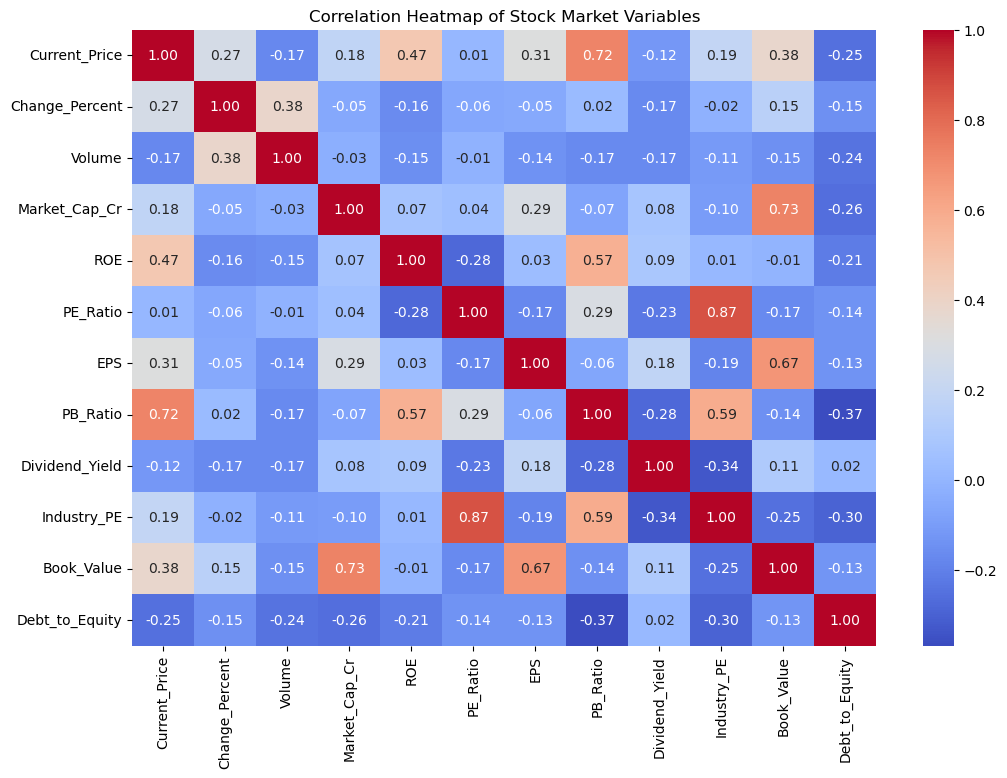

In [61]:
import seaborn as sns
import matplotlib.pyplot as plt

corr_matrix = final_df[
    [
        "Current_Price",
        "Change_Percent",
        "Volume",
        "Market_Cap_Cr",
        "ROE",
        "PE_Ratio",
        "EPS",
        "PB_Ratio",
        "Dividend_Yield",
        "Industry_PE",
        "Book_Value",
        "Debt_to_Equity"
    ]
].corr()

plt.figure(figsize=(12,8))

sns.heatmap(
    corr_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap of Stock Market Variables")

plt.show()

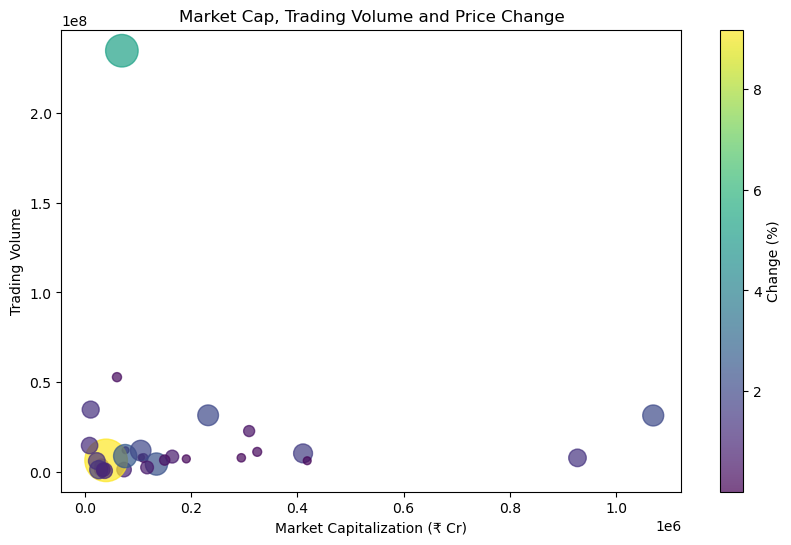

In [62]:
plt.figure(figsize=(10,6))

plt.scatter(
    final_df["Market_Cap_Cr"],
    final_df["Volume"],
    s=final_df["Change_Percent"].abs() * 100 + 20,
    c=final_df["Change_Percent"],
    alpha=0.7
)

plt.xlabel("Market Capitalization (₹ Cr)")
plt.ylabel("Trading Volume")
plt.title("Market Cap, Trading Volume and Price Change")

plt.colorbar(label="Change (%)")

plt.show()

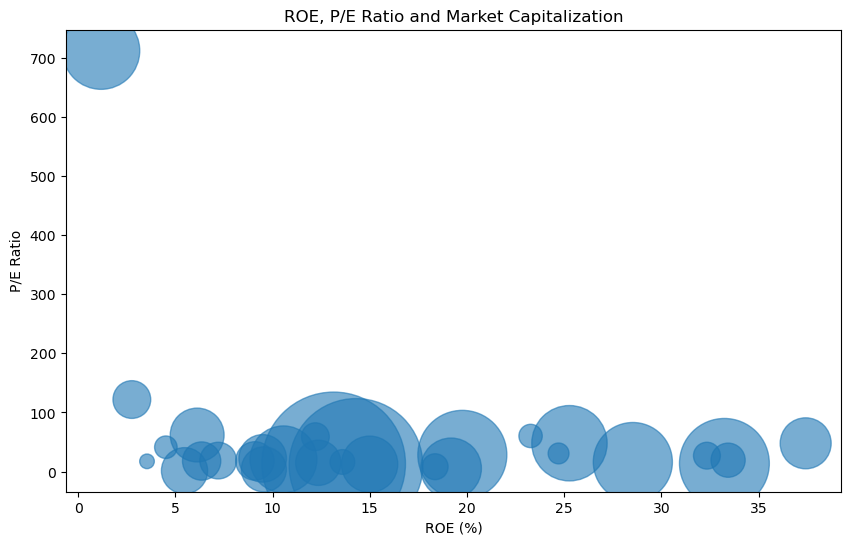

In [63]:
temp = final_df[
    ["ROE", "PE_Ratio", "Market_Cap_Cr"]
].dropna()

plt.figure(figsize=(10,6))

plt.scatter(
    temp["ROE"],
    temp["PE_Ratio"],
    s=temp["Market_Cap_Cr"] / 100,
    alpha=0.6
)

plt.xlabel("ROE (%)")
plt.ylabel("P/E Ratio")
plt.title("ROE, P/E Ratio and Market Capitalization")

plt.show()

In [64]:
final_df[
    ["Stock_Name", "Market_Cap_Cr"]
].sort_values(
    by="Market_Cap_Cr",
    ascending=False
).head(10)

,Stock_Name,Market_Cap_Cr
26,HDFC Bank,1069744
7,State Bank of India,927216
21,Infosys,418627
8,Adani Power,410764
2,ITC,324521
19,Zomato (Eternal),309294
25,Bharat Electronics,294584
12,Tata Steel,232131
15,Indian Oil Corporation,191060
3,Wipro,164571


In [65]:
final_df[
    ["Stock_Name", "Change_Percent"]
].sort_values(
    by="Change_Percent",
    ascending=False
).head(10)

,Stock_Name,Change_Percent
10,Cochin Shipyard,9.17
20,Yes Bank,5.29
17,SAIL,2.59
4,BSE,2.36
26,HDFC Bank,2.08
12,Tata Steel,2.02
27,Vedanta,1.99
8,Adani Power,1.65
11,SJVN,1.52
7,State Bank of India,1.39


In [66]:
final_df[
    ["Stock_Name", "Change_Percent"]
].sort_values(
    by="Change_Percent",
    ascending=True
).head(10)

,Stock_Name,Change_Percent
24,IRFC,0.01
1,NHPC,0.04
21,Infosys,0.12
15,Indian Oil Corporation,0.13
25,Bharat Electronics,0.16
0,Tata Motors,0.20
2,ITC,0.21
18,Suzlon Energy,0.23
14,Bharat Heavy Electricals,0.35
9,CDSL,0.37


In [67]:
final_df[
    ["Stock_Name", "ROE"]
].dropna().sort_values(
    by="ROE",
    ascending=False
).head(10)

,Stock_Name,ROE
4,BSE,37.42
18,Suzlon Energy,33.43
21,Infosys,33.24
23,IRCTC,32.34
2,ITC,28.53
25,Bharat Electronics,25.27
22,NBCC,24.71
9,CDSL,23.27
8,Adani Power,19.76
15,Indian Oil Corporation,19.18


In [68]:
final_df

,Stock_Name,Stock_URL,Current_Price,Change,Change_Percent,52_Week_Low,52_Week_High,Open_Price,Previous_Close,Volume,...,ROE,PE_Ratio,EPS,PB_Ratio,Dividend_Yield,Industry_PE,Book_Value,Debt_to_Equity,Face_Value,Distance_From_52W_High
0,Tata Motors,https://groww.in/stocks/tata-motors-ltd,301.10,0.60,0.20,294.30,447.79,299.75,300.50,7683193,...,5.47,1.39,215.87,0.99,1.00,26.14,304.29,0.71,2,32.758659
1,NHPC,https://groww.in/stocks/nhpc-ltd,76.38,0.03,0.04,71.62,89.22,75.91,76.35,12031109,...,9.09,17.98,4.25,1.85,2.11,23.44,41.25,1.26,10,14.391392
2,ITC,https://groww.in/stocks/itc-ltd,259.85,0.55,0.21,255.50,426.40,258.00,259.30,11116049,...,28.53,16.08,16.11,4.48,5.60,35.30,57.87,0.03,1,39.059568
3,Wipro,https://groww.in/stocks/wipro-ltd,167.40,1.10,0.66,166.00,273.10,165.20,166.30,8484897,...,14.99,12.39,13.41,1.87,7.01,17.93,88.75,0.23,2,38.703772
4,BSE,https://groww.in/stocks/bse-ltd,3384.00,78.00,2.36,2021.50,4446.80,3280.00,3306.00,4326473,...,37.42,47.79,69.18,20.21,0.30,46.80,163.60,0.00,2,23.900333
5,NTPC,https://groww.in/stocks/ntpc-green-energy-ltd,86.94,-0.78,0.89,84.00,119.95,87.70,87.72,1230861,...,2.76,121.86,0.72,3.90,0.00,23.44,22.51,1.67,10,27.519800
6,IREDA,https://groww.in/stocks/indian-renewable-energ...,111.71,-0.86,0.76,108.65,163.35,112.27,112.57,3342411,...,13.59,16.19,7.00,2.31,1.19,19.14,49.07,5.65,10,31.613101
7,State Bank of India,https://groww.in/stocks/state-bank-of-india,995.70,-14.00,1.39,810.40,1234.70,1000.00,1009.70,7771109,...,14.29,10.34,97.14,1.58,1.73,12.15,636.49,NaN,1,19.356929
8,Adani Power,https://groww.in/stocks/adani-power-ltd,209.97,-3.53,1.65,120.00,254.20,212.00,213.50,10271412,...,19.76,28.25,7.54,6.62,0.00,23.44,32.19,0.84,2,17.399685
9,CDSL,https://groww.in/stocks/central-depository-ser...,1360.00,5.00,0.37,1116.30,1673.70,1343.60,1355.00,1040559,...,23.27,60.22,22.50,14.45,0.94,46.80,93.77,0.00,10,18.742905
